# Workshop No. 1 â€” Exploratory Data Analysis (EDA)
## Machine Learning (Semester 2026-III) â€” Universidad Distrital Francisco JosÃ© de Caldas
### Domain: Real Estate Valuation â€” Ames Housing Dataset
**Instructor:** Eng. Carlos AndrÃ©s Sierra, M.Sc.  
**Team (Group 1):**
- Chavez Porras Miguel Alejandro (20212020033)
- Guerrero OrdeÃ±ez Luisa Fernanda (20212020099)
- Arboleda Zambrano Dilan Stive (20212020105)

---
### Notebook Objectives
1. Verify dataset integrity, variable types, and dimensions.
2. Characterize the target distribution (`SalePrice`) and evaluate log-transformation $\log(1 + y)$ for variance stabilization.
3. Identify and document missingness mechanisms (distinguishing real missing values from "feature absence").
4. Detect influential anomalies and outliers (specifically houses > 4,000 sq ft as highlighted by Dean De Cock).
5. Explore correlation structures and feature relationships to guide feature engineering and baseline model development.


In [1]:
import os
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

# Paths: traverse upward until we locate data/raw/AmesHousing.csv
current = Path.cwd().resolve()
RAW_DATA_PATH = None
for _ in range(5):
    candidate = current / "data" / "raw" / "AmesHousing.csv"
    if candidate.exists():
        RAW_DATA_PATH = candidate
        break
    current = current.parent

if RAW_DATA_PATH is None or not RAW_DATA_PATH.exists():
    raise FileNotFoundError("Could not find data/raw/AmesHousing.csv in parent directories")

print(f"Data path resolved: {RAW_DATA_PATH}")


Data path resolved: E:\Machine learning\ml-project-housing\data\raw\AmesHousing.csv


## 1. Dataset Ingestion and Structural Overview

In [2]:
df = pd.read_csv(RAW_DATA_PATH)
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(5)


Dataset Dimensions: 2930 rows, 82 columns


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [3]:
# Summary of data types
dtype_counts = df.dtypes.value_counts()
print("Data Types Breakdown:")
for dt, count in dtype_counts.items():
    print(f"  {str(dt):<12}: {count} columns")

num_cols = df.select_dtypes(include=[np.number]).columns.drop(["Order", "PID"], errors="ignore")
cat_cols = df.select_dtypes(exclude=[np.number]).columns
print(f"\nNumber of numeric features:     {len(num_cols)}")
print(f"Number of categorical features: {len(cat_cols)}")


Data Types Breakdown:
  str         : 43 columns
  int64       : 28 columns
  float64     : 11 columns

Number of numeric features:     37
Number of categorical features: 43


## 2. Target Variable Analysis (`SalePrice`)
We analyze the distribution of the target variable. Real estate prices typically exhibit right-skewness and heteroscedasticity due to high-value luxury properties.


In [4]:
sp = df["SalePrice"]
print(f"SalePrice Summary:")
print(f"  Count:          {sp.count():,}")
print(f"  Mean:           ${sp.mean():,.2f}")
print(f"  Median:         ${sp.median():,.2f}")
print(f"  Std Dev:        ${sp.std():,.2f}")
print(f"  Min:            ${sp.min():,}")
print(f"  25th Percentile:${sp.quantile(0.25):,}")
print(f"  75th Percentile:${sp.quantile(0.75):,}")
print(f"  Max:            ${sp.max():,}")
print(f"  Skewness:       {sp.skew():.3f}")
print(f"  Kurtosis:       {sp.kurtosis():.3f}")


SalePrice Summary:
  Count:          2,930
  Mean:           $180,796.06
  Median:         $160,000.00
  Std Dev:        $79,886.69
  Min:            $12,789
  25th Percentile:$129,500.0
  75th Percentile:$213,500.0
  Max:            $755,000
  Skewness:       1.744
  Kurtosis:       5.119


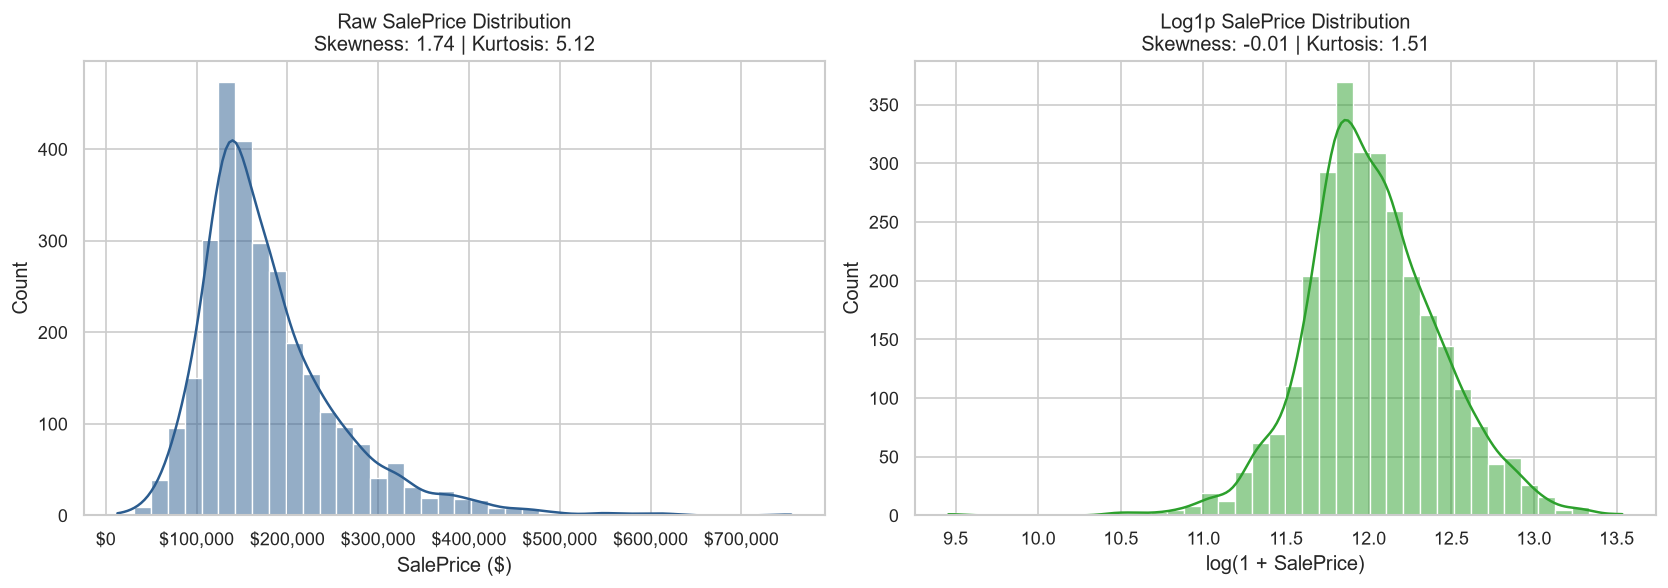

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw distribution
sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="#2b5c8f", bins=40)
axes[0].set_title(f"Raw SalePrice Distribution\nSkewness: {df['SalePrice'].skew():.2f} | Kurtosis: {df['SalePrice'].kurtosis():.2f}")
axes[0].set_xlabel("SalePrice ($)")
axes[0].xaxis.set_major_formatter("${x:,.0f}")

# Log-transformed
log_sp = np.log1p(df["SalePrice"])
sns.histplot(log_sp, kde=True, ax=axes[1], color="#2ca02c", bins=40)
axes[1].set_title(f"Log1p SalePrice Distribution\nSkewness: {log_sp.skew():.2f} | Kurtosis: {log_sp.kurtosis():.2f}")
axes[1].set_xlabel("log(1 + SalePrice)")

plt.tight_layout()
plt.show()


## 3. Missing Data Analysis: Distinguishing Missingness from Feature Absence
In the Ames Housing dataset, documentation confirms that for many features (`Alley`, `Bsmt Qual`, `Fireplace Qu`, `Garage Type`, `Pool QC`, `Fence`), `NA` does not represent missing information at random (MCAR/MAR), but rather the physical absence of that amenity.


In [6]:
missing = df.isnull().sum()
missing_pct = (missing[missing > 0] / len(df) * 100).sort_values(ascending=False)

print(f"Total columns with missing values: {len(missing_pct)}")
print(missing_pct.head(15))


Total columns with missing values: 27
Pool QC           99.556314
Misc Feature      96.382253
Alley             93.242321
Fence             80.477816
Mas Vnr Type      60.580205
Fireplace Qu      48.532423
Lot Frontage      16.723549
Garage Qual        5.426621
Garage Cond        5.426621
Garage Yr Blt      5.426621
Garage Finish      5.426621
Garage Type        5.358362
Bsmt Exposure      2.832765
BsmtFin Type 2     2.764505
Bsmt Cond          2.730375
dtype: float64


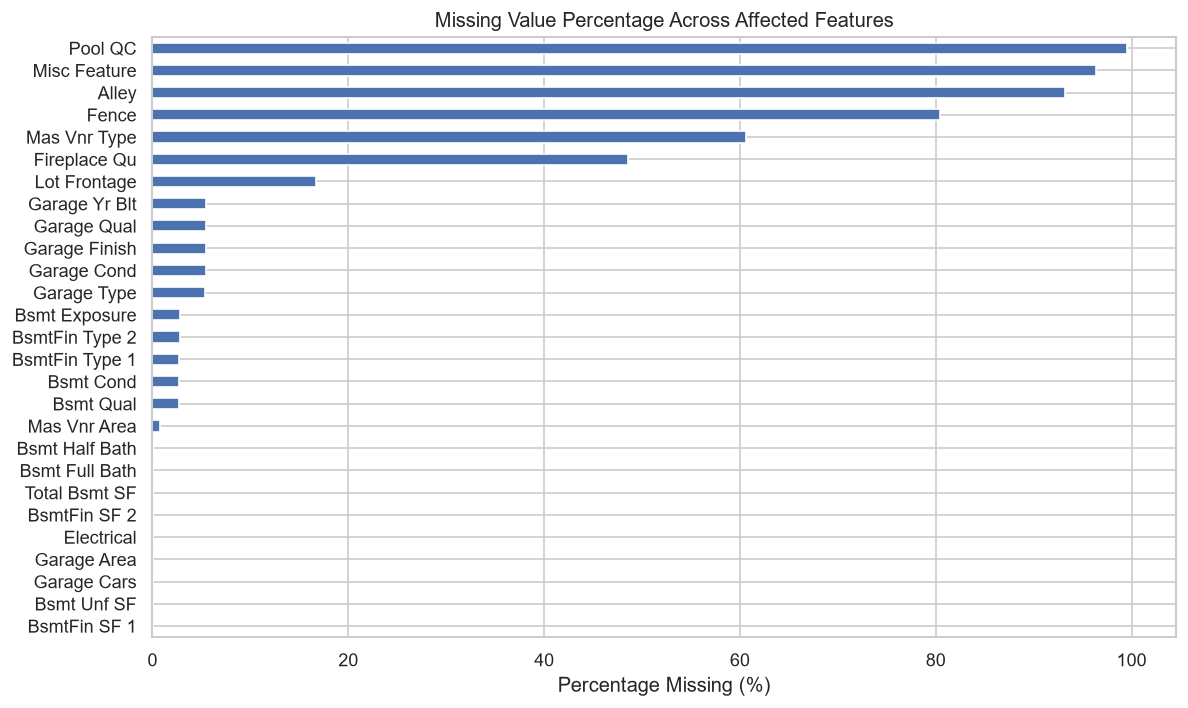

In [7]:
plt.figure(figsize=(10, 6))
missing_pct.sort_values(ascending=True).plot(kind="barh", color="#4c72b0")
plt.title("Missing Value Percentage Across Affected Features")
plt.xlabel("Percentage Missing (%)")
plt.tight_layout()
plt.show()


## 4. Influential Outliers: Above-Ground Living Area vs. SalePrice
Dean De Cock (2011) explicitly recommends removing observations with `Gr Liv Area` > 4,000 sq ft that do not represent typical residential transactions.


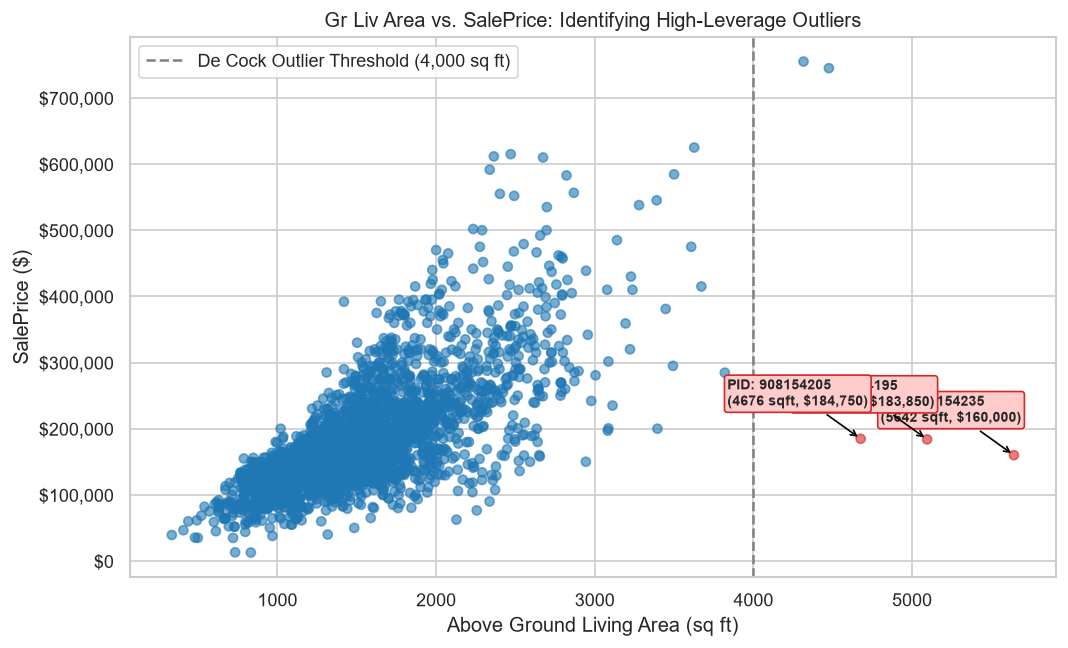

In [8]:
plt.figure(figsize=(9, 5.5))
outlier_mask = (df["Gr Liv Area"] > 4000) & (df["SalePrice"] < 300000)
colors = np.where(outlier_mask, "#d62728", "#1f77b4")
plt.scatter(df["Gr Liv Area"], df["SalePrice"], c=colors, alpha=0.6, s=30)
plt.axvline(x=4000, color="grey", linestyle="--", label="De Cock Outlier Threshold (4,000 sq ft)")

outliers = df[outlier_mask]
for _, r in outliers.iterrows():
    plt.annotate(f"PID: {r['PID']}\n({r['Gr Liv Area']} sqft, ${r['SalePrice']:,})",
                 (r["Gr Liv Area"], r["SalePrice"]),
                 xytext=(-80, 20), textcoords="offset points",
                 arrowprops=dict(arrowstyle="->", color="black", lw=1),
                 fontsize=8.5, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.2", fc="#ffcccc", ec="#d62728"))

plt.title("Gr Liv Area vs. SalePrice: Identifying High-Leverage Outliers")
plt.xlabel("Above Ground Living Area (sq ft)")
plt.ylabel("SalePrice ($)")
plt.gca().yaxis.set_major_formatter("${x:,.0f}")
plt.legend()
plt.tight_layout()
plt.show()


## 5. Feature Relationships and Correlation Matrix
We evaluate which numerical features possess the strongest linear correlation with `SalePrice`.


In [9]:
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=["Order", "PID"], errors="ignore")
correlations = numeric_df.corr()["SalePrice"].sort_values(ascending=False)

print("Top 15 Features Positively Correlated with SalePrice:")
print(correlations.head(16))


Top 15 Features Positively Correlated with SalePrice:
SalePrice         1.000000
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647877
Garage Area       0.640401
Total Bsmt SF     0.632280
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Garage Yr Blt     0.526965
Mas Vnr Area      0.508285
TotRms AbvGrd     0.495474
Fireplaces        0.474558
BsmtFin SF 1      0.432914
Lot Frontage      0.357318
Name: SalePrice, dtype: float64


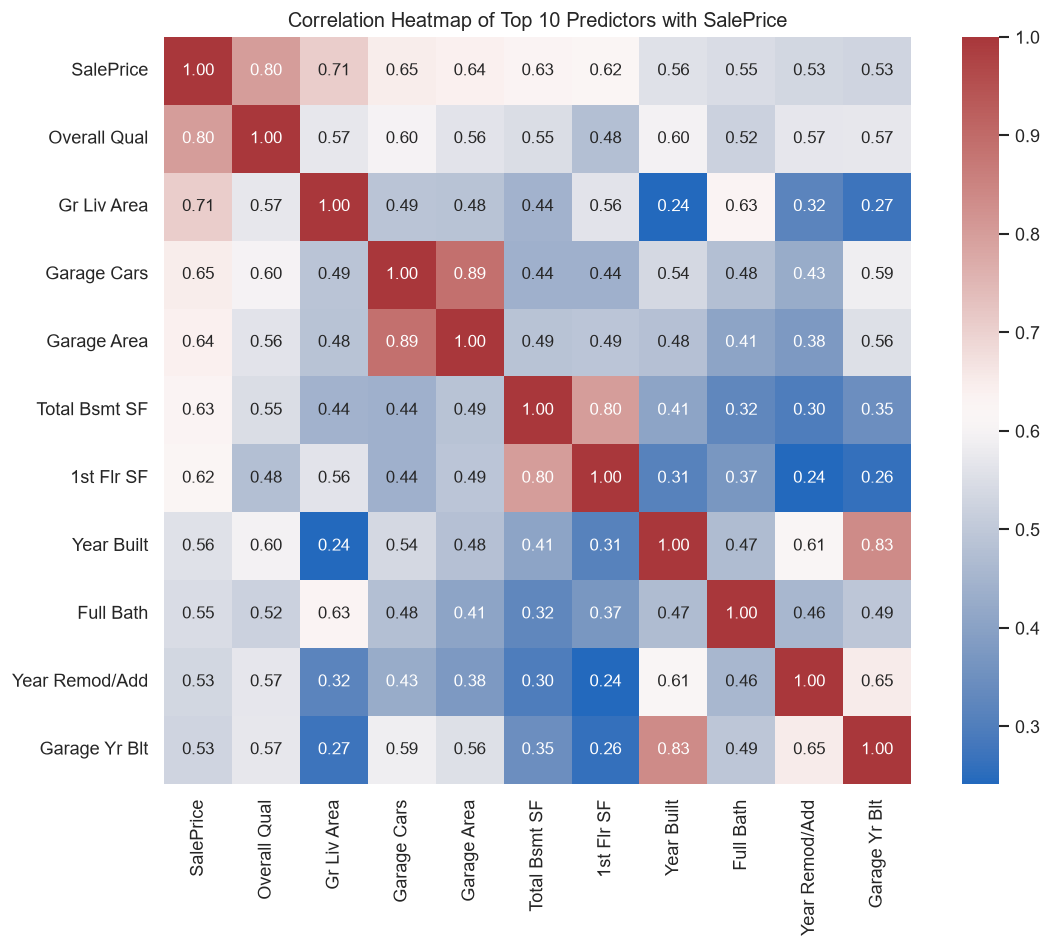

In [10]:
top_features = correlations.head(11).index
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df[top_features].corr(), annot=True, fmt=".2f", cmap="vlag", square=True)
plt.title("Correlation Heatmap of Top 10 Predictors with SalePrice")
plt.tight_layout()
plt.show()


## 6. Categorical Predictor Analysis
Analyzing quality ratings (`Overall Qual`) and spatial groupings (`Neighborhood`).


C:\Users\Danteeh\AppData\Local\Temp\ipykernel_18760\1373222567.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Overall Qual", y="SalePrice", data=df, ax=axes[0], palette="crest")
C:\Users\Danteeh\AppData\Local\Temp\ipykernel_18760\1373222567.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="SalePrice", y="Neighborhood", data=df, order=neigh_order, ax=axes[1],


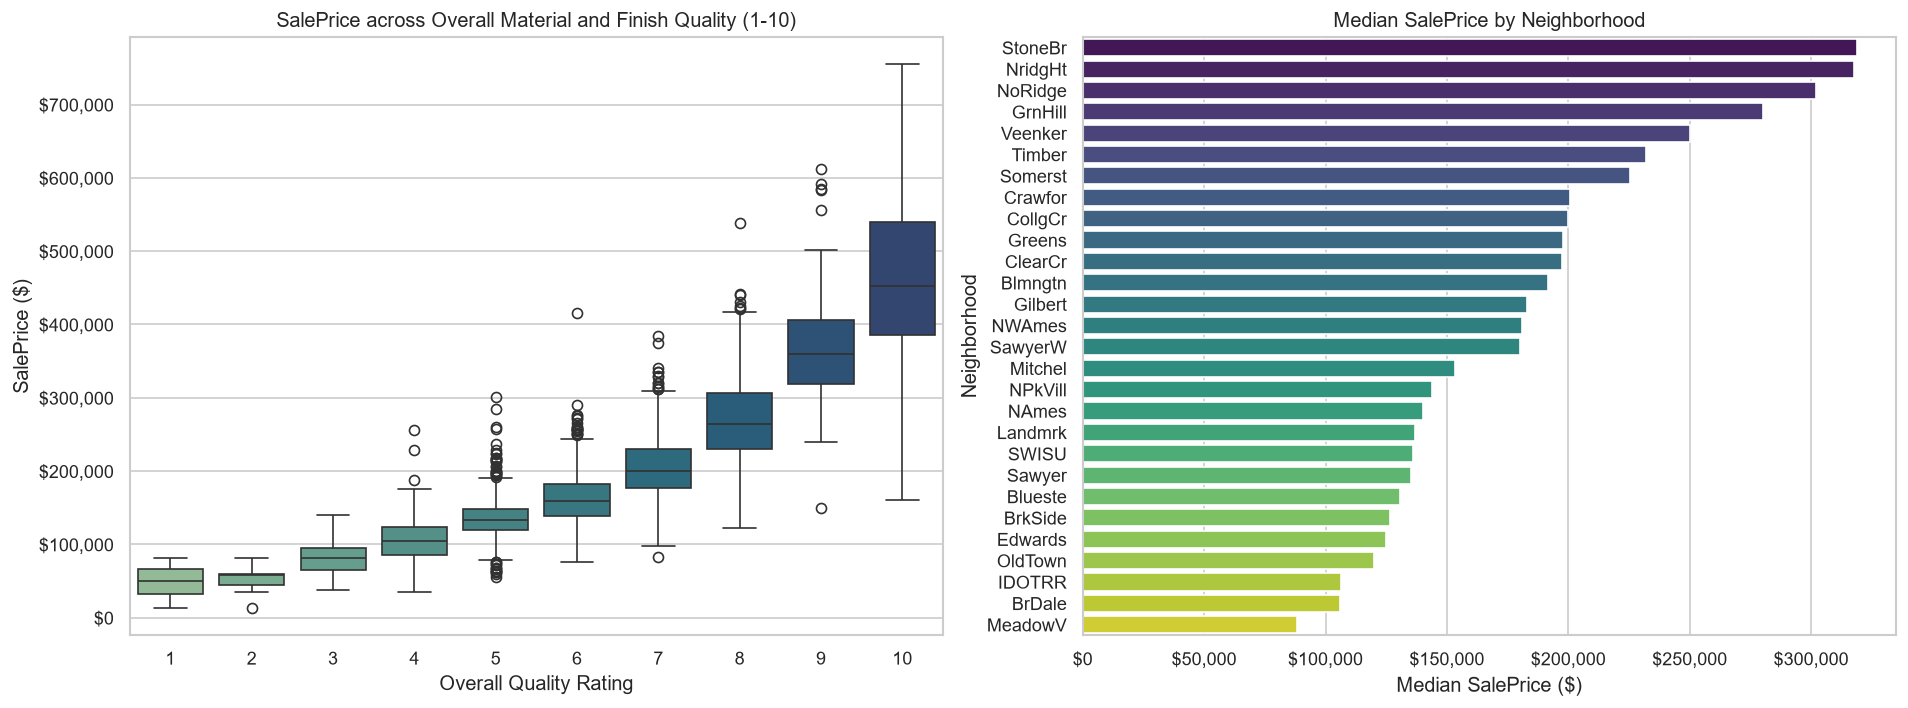

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(x="Overall Qual", y="SalePrice", data=df, ax=axes[0], palette="crest")
axes[0].set_title("SalePrice across Overall Material and Finish Quality (1-10)")
axes[0].set_xlabel("Overall Quality Rating")
axes[0].set_ylabel("SalePrice ($)")
axes[0].yaxis.set_major_formatter("${x:,.0f}")

neigh_order = df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).index
sns.barplot(x="SalePrice", y="Neighborhood", data=df, order=neigh_order, ax=axes[1],
            estimator=np.median, errorbar=None, palette="viridis")
axes[1].set_title("Median SalePrice by Neighborhood")
axes[1].set_xlabel("Median SalePrice ($)")
axes[1].xaxis.set_major_formatter("${x:,.0f}")

plt.tight_layout()
plt.show()


## 7. Key Findings & Recommendations for Modeling
1. **Target Transformation:** Model on $\log(1 + \text{SalePrice})$ to mitigate severe right skewness (+1.74) and stabilize residual variance.
2. **Outlier Treatment:** Remove the extreme outliers (> 4,000 sq ft with low price) exclusively during training set preprocessing to avoid distorting regression slopes.
3. **Domain Encoding:** Encode physical absence (`NA`) as an explicit `'None'` category for features like `GarageType`, `BsmtQual`, etc.
4. **Feature Engineering:** Create composite features such as `TotalSF` (living area + basement area) and `TotalBath`, which exhibit higher correlation than individual components.
5. **Leakage Prevention:** Compute all imputation values (e.g. median LotFrontage per neighborhood) and scaling parameters strictly on the training partition.
